# Análisis de sentimientos en texto con Machine Learning

**Universidad Pedagógica y Tecnológica de Colombia** · Escuela de Ingeniería de Sistemas y Computación · Inteligencia Computacional

**Taller:** Aplicación de algoritmos de Machine Learning en el Procesamiento de Lenguaje Natural

**Integrantes:** _(escribir los nombres del grupo)_

---

**Problema.** Construir un sistema que lea una frase, un párrafo o un documento en español y lo clasifique según la **emoción** que expresa: *Alegría, Tristeza, Enojo, Miedo, Sorpresa, Asco* o *Neutral*. A partir de la emoción se obtiene el **sentimiento** (positivo, negativo o neutral). Es una aplicación de **análisis de sentimiento**, una de las aplicaciones de PLN propuestas en el taller; las siete emociones son las clases ("temas") con las que se entrena el modelo.

**Flujo del notebook**

| # | Etapa | Sección |
|---|---|---|
| 1 | Carga del dataset | 2 |
| 2 | Limpieza | 3 |
| 3 | Tokenización | 4 |
| 4 | Stopwords y stemming | 5–6 |
| 5 | Representación (Bag of Words y TF-IDF) | 7 |
| 6 | Entrenamiento (Naive Bayes, Regresión logística, Árbol de decisión, Random Forest) | 8–9 |
| 7 | Evaluación (precisión, recall, F1, matriz de confusión, ROC y AUC) | 10–11 |
| 8 | Visualización (WordCloud, palabras clave) | 12 |
| 9 | Conclusiones | 13 |

## 1. Introducción: PLN y Machine Learning

El **Procesamiento de Lenguaje Natural (PLN)** es el área de la inteligencia artificial que permite a los computadores analizar y comprender texto escrito por personas. Un computador no entiende palabras, solo números; por eso todo proyecto de PLN sigue estas etapas:

1. **Preprocesamiento:** limpiar el texto y dividirlo en unidades (tokens), quitando lo que no aporta.
2. **Representación:** convertir cada texto en un vector numérico (Bag of Words, TF-IDF).
3. **Modelado:** entrenar un algoritmo de Machine Learning que aprende la relación entre esos vectores y las clases.
4. **Evaluación:** medir qué tan bien clasifica textos que nunca vio.

Aplicaciones reales: chatbots y asistentes virtuales, clasificación automática de correos o noticias, detección de spam y **análisis de sentimiento** de reseñas, encuestas o redes sociales (este proyecto).

### Instalación e importaciones
En Google Colab, la primera celda instala las librerías que no vienen por defecto.

In [1]:
%pip install -q emoji wordcloud nltk scikit-learn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import io, json, re, time, urllib.request, warnings
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, auc, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import label_binarize
from sklearn.tree import DecisionTreeClassifier
from wordcloud import WordCloud

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

EMOCIONES = ["Alegría", "Tristeza", "Enojo", "Miedo", "Sorpresa", "Asco", "Neutral"]
SENTIMIENTO = {"Alegría": "Positivo", "Sorpresa": "Neutral", "Neutral": "Neutral",
               "Tristeza": "Negativo", "Enojo": "Negativo", "Miedo": "Negativo", "Asco": "Negativo"}
COLORES = {"Alegría": "#E8B21F", "Tristeza": "#3B7DD8", "Enojo": "#D9483B", "Miedo": "#7C4DBF",
           "Sorpresa": "#E07A1F", "Asco": "#3C9A5F", "Neutral": "#8A8F98"}
CARPETA_DATOS, CARPETA_RESULTADOS, CARPETA_MODELO = Path("datos"), Path("resultados"), Path("modelo")
for c in (CARPETA_DATOS, CARPETA_RESULTADOS, CARPETA_MODELO):
    c.mkdir(exist_ok=True)
SEMILLA = 42

## 2. Carga del dataset

Se usan dos corpus públicos en español etiquetados por personas:

| Corpus | Textos | Descripción |
|---|---|---|
| **EmoEvent** (Plaza-del-Arco et al., 2020) | ~8.400 | Tuits sobre eventos de abril de 2019 (Notre Dame, Juego de Tronos, Champions League, elecciones en España…) |
| **BRIGHTER / SemEval-2025 Tarea 11** (Muhammad et al., 2025) | ~3.900 | Comentarios de redes sociales con estilo más latinoamericano |

Cada corpus ya viene dividido en **entrenamiento**, **validación** y **prueba**. Se respetan esas divisiones:
- **Entrenamiento:** para que el modelo aprenda.
- **Validación:** para elegir los hiperparámetros de cada modelo.
- **Prueba:** solo para la evaluación final (textos que el modelo nunca vio).

Decisiones de preparación:
- En BRIGHTER un texto puede tener varias emociones. En entrenamiento se repite una vez por emoción; en validación y prueba solo se usan textos con una sola emoción.
- **Corrección de etiquetas:** en el repositorio de EmoEvent, las etiquetas de `test.tsv` no corresponden a los tuits (solo ~35 % coincide con el corpus completo). Se toman las etiquetas correctas de `emoevent_es.csv`.

In [3]:
URL_EMOEVENT = "https://raw.githubusercontent.com/fmplaza/EmoEvent/master/splits/es/{}.tsv"
URL_EMOEVENT_COMPLETO = "https://raw.githubusercontent.com/fmplaza/EmoEvent/master/emoevent_es.csv"
URL_BRIGHTER = ("https://raw.githubusercontent.com/emotion-analysis-project/SemEval2025-task11/main/"
                "task-dataset/semeval-2025-task11-dataset/track_a/{}/esp.csv")
TRADUCCION = {"joy": "Alegría", "sadness": "Tristeza", "anger": "Enojo", "fear": "Miedo",
              "surprise": "Sorpresa", "disgust": "Asco", "others": "Neutral"}


def descargar(url, nombre):
    """Descarga un archivo una sola vez y lo guarda en datos/originales/."""
    ruta = CARPETA_DATOS / "originales" / nombre
    if not ruta.exists():
        ruta.parent.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(url, timeout=60) as r:
            ruta.write_bytes(r.read())
    return io.StringIO(ruta.read_text(encoding="utf-8"))


def clave(texto):
    """Huella de un tuit sin enlaces, hashtags ni menciones, para cruzar archivos."""
    t = re.sub(r"https?://\S+|\bURL\b|#\w+|\bHASHTAG\b|@\w+|\bUSER\b", "", str(texto))
    return re.sub(r"\W+", "", t.lower())[:60]


completo = pd.read_csv(descargar(URL_EMOEVENT_COMPLETO, "emoevent_es.csv"), sep="\t")
etiqueta_correcta = dict(zip(completo["tweet"].map(clave), completo["emotion"]))


def cargar_emoevent(particion):
    df = pd.read_csv(descargar(URL_EMOEVENT.format(particion), f"emoevent_{particion}.tsv"), sep="\t")
    etiqueta = df["tweet"].map(clave).map(etiqueta_correcta)
    corregidas = int((etiqueta.notna() & (etiqueta != df["emotion"])).sum())
    print(f"EmoEvent {particion}: {len(df)} tuits, {corregidas} etiquetas corregidas")
    return pd.DataFrame({"texto": df["tweet"], "emocion": etiqueta.map(TRADUCCION), "fuente": "EmoEvent"})


def cargar_brighter(particion, repetir_multiples):
    df = pd.read_csv(descargar(URL_BRIGHTER.format(particion), f"brighter_{particion}.csv"))
    columnas = ["anger", "disgust", "fear", "joy", "sadness", "surprise"]
    filas = []
    for _, fila in df.iterrows():
        emociones = [c for c in columnas if fila[c] == 1]
        if emociones and (len(emociones) == 1 or repetir_multiples):
            filas += [{"texto": fila["text"], "emocion": TRADUCCION[e], "fuente": "BRIGHTER"} for e in emociones]
    return pd.DataFrame(filas)


def preparar(df):
    df = df.dropna(subset=["texto", "emocion"]).copy()
    df["texto"] = df["texto"].astype(str).str.strip().str.strip('"').str.strip()
    return df[df["texto"].str.len() > 2].drop_duplicates(subset=["texto", "emocion"])


train = preparar(pd.concat([cargar_emoevent("train"), cargar_brighter("train", True)]))
valid = preparar(pd.concat([cargar_emoevent("dev"), cargar_brighter("dev", False)]))
test = preparar(pd.concat([cargar_emoevent("test"), cargar_brighter("test", False)]))
# Ningún texto de validación o prueba puede estar en entrenamiento
train = train[~train["texto"].isin(set(valid["texto"]) | set(test["texto"]))]
train, valid, test = (d.sample(frac=1, random_state=SEMILLA).reset_index(drop=True) for d in (train, valid, test))
print(f"\nEntrenamiento: {len(train)} | Validación: {len(valid)} | Prueba: {len(test)}")

EmoEvent train: 5723 tuits, 6 etiquetas corregidas
EmoEvent dev: 844 tuits, 0 etiquetas corregidas
EmoEvent test: 1656 tuits, 1050 etiquetas corregidas



Entrenamiento: 8534 | Validación: 958 | Prueba: 2722


In [4]:
train.sample(8, random_state=1)[["texto", "emocion", "fuente"]]

,texto,emocion,fuente
3576,"Y entre la lluvia, la tormenta y el sol un sinfín de palabras con alas que nos llevan a los lugares más recónditos d...",Alegría,EmoEvent
3074,El #Ajax juega muy bien y no quiero desmerecer su triunfo de ayer ante los #Spurs por la #ChampionsLeague pero le ha...,Tristeza,EmoEvent
911,"La #Joven activista sueca #GretaThunberg, voz prominente en la lucha contra el #CambioClimático, ha sido nominada al...",Alegría,EmoEvent
7365,"Joder Messi, echale el freno de mano #BarcelonaLiverpool #ChampionsLeague",Sorpresa,EmoEvent
8385,#GameofThrones #JuegoDeTronos #ForTheThrone 8x03 En serio estoy por dejar de verlo,Neutral,EmoEvent
7552,La gran noche! Hoy recibimos a uno de los mejores equipos de Europa e Inglaterra; repleto de excelentes jugadores. A...,Alegría,EmoEvent
8339,Que espectáculo lo de Sadio Mane. #ChampionsLeague,Neutral,EmoEvent
103,"Yo no donaba para reconstruir la catedral de #NotreDame NO MAMEN, mejor donen para re construir bosques y hacer rese...",Enojo,EmoEvent


### Distribución de las clases
El dataset está **desbalanceado**: hay muchos más textos neutrales y de alegría que de miedo. Esto se tiene en cuenta al entrenar (pesos por clase) y al evaluar (se usa F1 *macro*, que pesa igual a todas las emociones).

,Entrenamiento,Validación,Prueba,Total
emocion,,,,
Alegría,1867,213,712,2792
Tristeza,1000,122,355,1477
Enojo,1081,93,240,1414
Miedo,382,31,141,554
Sorpresa,658,52,276,986
Asco,765,38,204,1007
Neutral,2781,409,794,3984


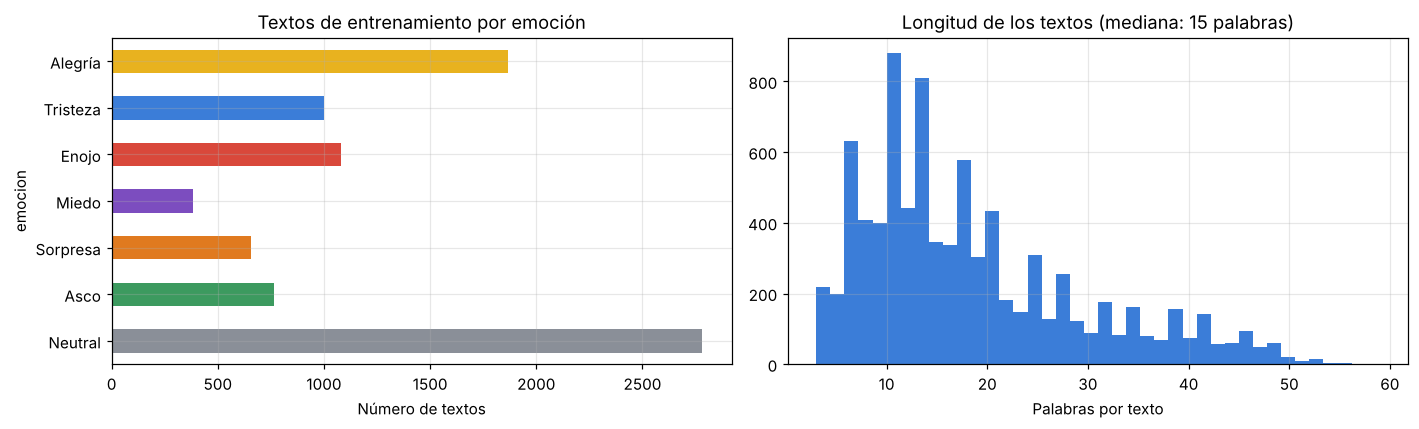

In [5]:
conteo = pd.DataFrame({n: d["emocion"].value_counts() for n, d in
                       [("Entrenamiento", train), ("Validación", valid), ("Prueba", test)]}).loc[EMOCIONES]
display(conteo.assign(Total=conteo.sum(axis=1)))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
conteo["Entrenamiento"].plot.barh(ax=ejes[0], color=[COLORES[e] for e in EMOCIONES])
ejes[0].invert_yaxis(); ejes[0].set_title("Textos de entrenamiento por emoción"); ejes[0].set_xlabel("Número de textos")
largo = train["texto"].str.split().str.len()
ejes[1].hist(largo.clip(upper=80), bins=40, color="#3B7DD8")
ejes[1].set_title(f"Longitud de los textos (mediana: {largo.median():.0f} palabras)"); ejes[1].set_xlabel("Palabras por texto")
plt.tight_layout(); plt.show()

## 3–6. Preprocesamiento del texto

El preprocesamiento se hace en cuatro pasos. La siguiente celda define las funciones (el mismo código está en `src/preprocesamiento.py`, que usa la aplicación web, para que el texto se procese igual al entrenar y al predecir).

| Paso | Función | Qué hace |
|---|---|---|
| 3. Limpieza | `limpiar` | Elimina enlaces, menciones y símbolos; convierte emojis y emoticones en palabras; normaliza risas y letras repetidas; pasa a minúsculas |
| 4. Tokenización | `tokenizar` | Divide el texto en palabras (tokens); conserva `!` y `?` porque expresan emoción |
| 5. Stopwords | `quitar_stopwords` | Quita palabras muy frecuentes sin significado propio ("de", "la", "que"), **excepto** negaciones e intensificadores |
| 6. Stemming | `aplicar_stemming` | Reduce cada palabra a su raíz con el algoritmo Snowball para español |

In [6]:
import html
import re

import emoji
import nltk
from nltk.stem import SnowballStemmer

# ---------------------------------------------------------------------------
# 1. LIMPIEZA: quita enlaces, menciones y símbolos; normaliza emojis y risas
# ---------------------------------------------------------------------------
EMOTICONES = [
    (r"(?<!\S)[:;=]-?[)\]]+", " emoticono_feliz "),     # :)  ;)  =)
    (r"(?<!\S)[:;=]-?D+\b", " emoticono_risa "),        # :D
    (r"(?<!\S)[:;=]'?-?[(\[]+", " emoticono_triste "),  # :(  :'(
    (r"<3+", " emoticono_corazon "),                     # <3
]


def limpiar(texto: str) -> str:
    t = html.unescape(str(texto))                                     # &amp; -> &
    t = re.sub(r"https?://\S+|www\.\S+|\bURL\b", " ", t)             # enlaces
    t = re.sub(r"@<username>|@\w+|\bUSER\b|\bHASHTAG\b", " ", t)     # menciones
    t = re.sub(r"#(\w+)", r" \1 ", t)                                # #feliz -> feliz
    for patron, palabra in EMOTICONES:                               # :( -> emoticono_triste
        t = re.sub(patron, palabra, t)
    t = emoji.demojize(t, language="es", delimiters=(" emoji_", " "))  # 😭 -> emoji_cara_llorando_fuerte
    t = t.lower().replace("¡", "!").replace("¿", "?")
    t = re.sub(r"\b(?:a?j+[aeiou]+){2,}j?\b|\b(?:h+a+){2,}h?\b|\bj+s+j[js]*\b|\bxd+\b",
               " jaja ", t)                                          # jajajaja, jsjs, xD -> jaja
    t = re.sub(r"(\w)\1{2,}", r"\1\1", t)                            # siiiii -> sii
    t = re.sub(r"([!?])\1{2,}", r"\1\1", t)                          # !!!!! -> !!
    return t


# ---------------------------------------------------------------------------
# 2. TOKENIZACIÓN: divide el texto en palabras (tokens)
#    Se conservan las palabras (incluidos los emojis convertidos) y los signos
#    ! y ?, que expresan emoción. Números y demás símbolos se descartan.
# ---------------------------------------------------------------------------
def tokenizar(texto: str) -> list[str]:
    return re.findall(r"[a-záéíóúüñ_]+|[!?]", texto)


# ---------------------------------------------------------------------------
# 3. STOPWORDS: elimina palabras muy frecuentes que no aportan significado
#    Se usa la lista de NLTK para español (313 palabras), pero se CONSERVAN
#    las que cambian la emoción de la frase (negaciones, intensificadores...).
# ---------------------------------------------------------------------------
try:
    from nltk.corpus import stopwords
    _LISTA_NLTK = stopwords.words("spanish")
except LookupError:
    nltk.download("stopwords", quiet=True)
    from nltk.corpus import stopwords
    _LISTA_NLTK = stopwords.words("spanish")

PALABRAS_A_CONSERVAR = {
    "no", "ni", "sin", "nada", "nunca", "pero", "contra",            # negación y contraste
    "muy", "mucho", "qué", "sí",                                     # intensidad y exclamación
    "siente", "sentido", "sentida", "sentidos", "sentidas", "sintiendo",
    "tengo", "tiene",                                                # "tengo miedo", "me siente mal"
}
STOPWORDS = set(_LISTA_NLTK) - PALABRAS_A_CONSERVAR


def quitar_stopwords(tokens: list[str]) -> list[str]:
    return [t for t in tokens if t not in STOPWORDS]


# ---------------------------------------------------------------------------
# 4. STEMMING: reduce cada palabra a su raíz (algoritmo Snowball para español)
#    felicidad, felices -> felic ; tristeza -> tristez ; llorando -> llor
#    Los emojis convertidos, la risa y los signos no se modifican.
# ---------------------------------------------------------------------------
_stemmer = SnowballStemmer("spanish")
_SIN_STEMMING = ("emoji_", "emoticono_")


def aplicar_stemming(tokens: list[str]) -> list[str]:
    return [
        t if t.startswith(_SIN_STEMMING) or t in {"!", "?", "jaja"} else _stemmer.stem(t)
        for t in tokens
    ]


# ---------------------------------------------------------------------------
# PREPROCESAMIENTO COMPLETO: limpieza -> tokenización -> stopwords -> stemming
# Devuelve los tokens unidos por espacios (lo que recibe el vectorizador).
# ---------------------------------------------------------------------------
def preprocesar(texto: str, quitar_stop: bool = True, stemming: bool = True) -> str:
    tokens = tokenizar(limpiar(texto))
    if quitar_stop:
        tokens = quitar_stopwords(tokens)
    if stemming:
        tokens = aplicar_stemming(tokens)
    return " ".join(tokens)

### 3. Limpieza
Los textos de redes sociales tienen enlaces, menciones, emojis y risas escritas de muchas formas. La limpieza los deja en un formato uniforme. Los **emojis no se eliminan**, sino que se convierten en palabras, porque expresan emociones (😭 → `emoji_cara_llorando_fuerte`).

In [7]:
ejemplos = [
    "@ana ¡¡No puedo creerlo!!! 😭😭 https://t.co/abc #triste",
    "JAJAJAJA qué risa xD, estoy feliiiiz :)",
    "Me da mucho miedo caminar sola por esa calle de noche",
    "Qué asco, encontré un pelo en la sopa del restaurante 🤢",
]
pd.DataFrame({"Original": ejemplos, "Limpio": [limpiar(t) for t in ejemplos]})

,Original,Limpio
0,@ana ¡¡No puedo creerlo!!! 😭😭 https://t.co/abc #triste,!!no puedo creerlo!! emoji_cara_llorando_fuerte emoji_cara_llorando_fuerte triste
1,"JAJAJAJA qué risa xD, estoy feliiiiz :)","jaja qué risa jaja , estoy feliiz emoticono_feliz"
2,Me da mucho miedo caminar sola por esa calle de noche,me da mucho miedo caminar sola por esa calle de noche
3,"Qué asco, encontré un pelo en la sopa del restaurante 🤢","qué asco, encontré un pelo en la sopa del restaurante emoji_cara_de_náuseas"


### 4. Tokenización
La tokenización divide el texto limpio en unidades llamadas **tokens** (normalmente palabras). Se usa una expresión regular que conserva las palabras con tildes y ñ, los emojis convertidos y los signos `!` y `?`. Los números y demás símbolos se descartan.

In [8]:
for t in ejemplos[:2]:
    print(f"{t}\n  -> {tokenizar(limpiar(t))}\n")

tokens_train = train["texto"].map(lambda t: tokenizar(limpiar(t)))
print(f"Tokens en entrenamiento: {tokens_train.str.len().sum():,}")
print(f"Palabras distintas (vocabulario): {len(set(w for ts in tokens_train for w in ts)):,}")

@ana ¡¡No puedo creerlo!!! 😭😭 https://t.co/abc #triste
  -> ['!', '!', 'no', 'puedo', 'creerlo', '!', '!', 'emoji_cara_llorando_fuerte', 'emoji_cara_llorando_fuerte', 'triste']

JAJAJAJA qué risa xD, estoy feliiiiz :)
  -> ['jaja', 'qué', 'risa', 'jaja', 'estoy', 'feliiz', 'emoticono_feliz']



Tokens en entrenamiento: 156,967
Palabras distintas (vocabulario): 16,696


### 5. Eliminación de stopwords
Las **stopwords** son palabras muy frecuentes (artículos, preposiciones, pronombres) que casi no aportan al significado. Se usa la lista de NLTK para español (313 palabras), **excepto** un grupo de palabras que sí cambian la emoción de una frase: no es lo mismo "estoy feliz" que "**no** estoy feliz", ni "miedo" que "**mucho** miedo".

In [9]:
print(f"Stopwords de NLTK: {len(_LISTA_NLTK)} | Se conservan: {sorted(PALABRAS_A_CONSERVAR)}")
print(f"Stopwords que se eliminan: {len(STOPWORDS)}\n")

frecuentes = pd.Series([w for ts in tokens_train for w in ts]).value_counts().head(15)
sin_stop = pd.Series([w for ts in tokens_train for w in quitar_stopwords(ts)]).value_counts().head(15)
pd.DataFrame({"Más frecuentes (antes)": frecuentes.index, "n": frecuentes.values,
              "Más frecuentes (sin stopwords)": sin_stop.index, "n ": sin_stop.values})

Stopwords de NLTK: 313 | Se conservan: ['contra', 'mucho', 'muy', 'nada', 'ni', 'no', 'nunca', 'pero', 'qué', 'sentida', 'sentidas', 'sentido', 'sentidos', 'siente', 'sin', 'sintiendo', 'sí', 'tengo', 'tiene']
Stopwords que se eliminan: 295



,Más frecuentes (antes),n,Más frecuentes (sin stopwords),n
0,de,6915,no,2285
1,que,5181,!,2214
2,la,4410,?,1324
3,a,4326,eleccionesgenerales,907
4,el,3965,juegodetronos,889
5,y,3360,championsleague,815
6,en,2925,venezuela,803
7,no,2285,notredame,793
8,!,2214,si,578
9,los,2057,pero,560


### 6. Stemming (raíces)
El **stemming** recorta cada palabra a su raíz para que variantes de la misma palabra cuenten como una sola: *felicidad, felices → felic*; *tristeza → tristez*; *llorando → llor*. Se usa el **Snowball Stemmer** para español de NLTK.

> **Stemming vs. lematización:** la lematización devuelve la forma de diccionario (*corriendo → correr*) usando análisis gramatical; es más precisa pero más lenta y requiere modelos adicionales (por ejemplo spaCy). El stemming solo recorta sufijos con reglas, es muy rápido y para clasificación de texto suele funcionar igual de bien.

In [10]:
palabras = ["felicidad", "felices", "feliz", "tristeza", "tristes", "llorando", "lloré", "miedoso", "asquerosa", "enojado"]
pd.DataFrame({"Palabra": palabras, "Raíz (stem)": aplicar_stemming(palabras)}).T

,0,1,2,3,4,5,6,7,8,9
Palabra,felicidad,felices,feliz,tristeza,tristes,llorando,lloré,miedoso,asquerosa,enojado
Raíz (stem),felic,felic,feliz,tristez,trist,llor,llor,miedos,asquer,enoj


### Preprocesamiento completo
Se aplican los cuatro pasos a todos los textos. La tabla muestra el efecto acumulado en algunos ejemplos.

In [11]:
pasos = pd.DataFrame({
    "Original": ejemplos,
    "Tokens": [tokenizar(limpiar(t)) for t in ejemplos],
    "Sin stopwords": [quitar_stopwords(tokenizar(limpiar(t))) for t in ejemplos],
    "Final (con stemming)": [preprocesar(t) for t in ejemplos],
})
display(pasos)

for df in (train, valid, test):
    df["procesado"] = df["texto"].map(preprocesar)

,Original,Tokens,Sin stopwords,Final (con stemming)
0,@ana ¡¡No puedo creerlo!!! 😭😭 https://t.co/abc #triste,"[!, !, no, puedo, creerlo, !, !, emoji_cara_llorando_fuerte, emoji_cara_llorando_fuerte, triste]","[!, !, no, puedo, creerlo, !, !, emoji_cara_llorando_fuerte, emoji_cara_llorando_fuerte, triste]",! ! no pued cre ! ! emoji_cara_llorando_fuerte emoji_cara_llorando_fuerte trist
1,"JAJAJAJA qué risa xD, estoy feliiiiz :)","[jaja, qué, risa, jaja, estoy, feliiz, emoticono_feliz]","[jaja, qué, risa, jaja, feliiz, emoticono_feliz]",jaja que ris jaja feliiz emoticono_feliz
2,Me da mucho miedo caminar sola por esa calle de noche,"[me, da, mucho, miedo, caminar, sola, por, esa, calle, de, noche]","[da, mucho, miedo, caminar, sola, calle, noche]",da much mied camin sol call noch
3,"Qué asco, encontré un pelo en la sopa del restaurante 🤢","[qué, asco, encontré, un, pelo, en, la, sopa, del, restaurante, emoji_cara_de_náuseas]","[qué, asco, encontré, pelo, sopa, restaurante, emoji_cara_de_náuseas]",que asco encontr pel sop restaur emoji_cara_de_náuseas


### ¿Ayuda el preprocesamiento?
Para comprobarlo, se entrena el mismo modelo (TF-IDF + Regresión logística) con cuatro variantes del preprocesamiento y se compara el F1 macro en **validación**.

In [12]:
variantes = {"Solo limpieza y tokenización": dict(quitar_stop=False, stemming=False),
             "+ quitar stopwords": dict(quitar_stop=True, stemming=False),
             "+ stemming": dict(quitar_stop=False, stemming=True),
             "+ stopwords + stemming": dict(quitar_stop=True, stemming=True)}
filas = []
for nombre, opciones in variantes.items():
    xtr = train["texto"].map(lambda t: preprocesar(t, **opciones))
    xva = valid["texto"].map(lambda t: preprocesar(t, **opciones))
    vec = TfidfVectorizer(token_pattern=r"\S+", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    clf = LogisticRegression(C=4, max_iter=3000, class_weight="balanced").fit(vec.fit_transform(xtr), train["emocion"])
    pred = clf.predict(vec.transform(xva))
    filas.append({"Preprocesamiento": nombre, "Vocabulario": len(vec.vocabulary_),
                  "Accuracy (val)": accuracy_score(valid["emocion"], pred),
                  "F1 macro (val)": f1_score(valid["emocion"], pred, average="macro")})
tabla_prep = pd.DataFrame(filas)
tabla_prep.style.format({"Accuracy (val)": "{:.1%}", "F1 macro (val)": "{:.1%}", "Vocabulario": "{:,}"})

,Preprocesamiento,Vocabulario,Accuracy (val),F1 macro (val)
0,Solo limpieza y tokenización,"25,506",65.2%,60.7%
1,+ quitar stopwords,"16,477",64.8%,60.7%
2,+ stemming,"23,628",65.4%,61.3%
3,+ stopwords + stemming,"15,257",66.2%,63.1%


## 7. Representación: Bag of Words y TF-IDF

Los modelos necesitan números. Las dos representaciones clásicas convierten cada texto en un vector con una posición por cada término del vocabulario:

- **Bag of Words (BoW):** cuenta cuántas veces aparece cada término. Ignora el orden de las palabras (por eso "bolsa de palabras").
- **TF-IDF:** multiplica la frecuencia del término en el texto (**TF**) por su rareza en todo el corpus (**IDF**). Así, las palabras que aparecen en casi todos los textos pesan poco y las distintivas pesan más.

$$\text{tf-idf}(t, d) = \underbrace{(1 + \ln \text{tf}_{t,d})}_{\text{frecuencia}} \times \underbrace{\left(\ln\frac{1+N}{1+\text{df}_t} + 1\right)}_{\text{rareza}}$$

donde $N$ es el número de textos y $\text{df}_t$ el número de textos que contienen el término $t$. Cada vector se normaliza a longitud 1.

En ambas se usan **unigramas y bigramas** (palabras sueltas y pares de palabras seguidas, como *"no feliz"*), y se descartan los términos que aparecen en un solo texto.

**Ejemplo con tres frases:**

In [13]:
mini = ["Me encanta este día soleado", "Odio este día lluvioso", "Me encanta la lluvia, me encanta"]
mini_proc = [preprocesar(t) for t in mini]
print("Frases preprocesadas:", mini_proc)
bow_mini = CountVectorizer(token_pattern=r"\S+")
tfidf_mini = TfidfVectorizer(token_pattern=r"\S+")
display(pd.DataFrame(bow_mini.fit_transform(mini_proc).toarray(), columns=bow_mini.get_feature_names_out(),
                     index=[f"Frase {i+1}" for i in range(3)]).style.set_caption("Bag of Words (conteos)"))
display(pd.DataFrame(tfidf_mini.fit_transform(mini_proc).toarray(), columns=tfidf_mini.get_feature_names_out(),
                     index=[f"Frase {i+1}" for i in range(3)]).round(2).style.set_caption("TF-IDF"))

Frases preprocesadas: ['encant dia sol', 'odi dia lluvios', 'encant lluvi encant']


,dia,encant,lluvi,lluvios,odi,sol
Frase 1,1,1,0,0,0,1
Frase 2,1,0,0,1,1,0
Frase 3,0,2,1,0,0,0


,dia,encant,lluvi,lluvios,odi,sol
Frase 1,0.520000,0.520000,0.000000,0.000000,0.000000,0.680000
Frase 2,0.470000,0.000000,0.000000,0.620000,0.620000,0.000000
Frase 3,0.000000,0.840000,0.550000,0.000000,0.000000,0.000000


En BoW, *"encant"* vale 2 en la frase 3 solo porque se repite. En TF-IDF, *"dia"* (presente en dos frases) pesa menos que *"lluvi"* o *"sol"*, que son más distintivas.

**Vectorización del dataset completo** (el vocabulario se aprende solo con los textos de entrenamiento):

In [14]:
REPRESENTACIONES = {
    "Bag of Words": CountVectorizer(token_pattern=r"\S+", ngram_range=(1, 2), min_df=2),
    "TF-IDF": TfidfVectorizer(token_pattern=r"\S+", ngram_range=(1, 2), min_df=2, sublinear_tf=True),
}
X = {}
for nombre, vectorizador in REPRESENTACIONES.items():
    X[nombre] = (vectorizador.fit_transform(train["procesado"]),
                 vectorizador.transform(valid["procesado"]),
                 vectorizador.transform(test["procesado"]))
    m = X[nombre][0]
    print(f"{nombre:13}: matriz de {m.shape[0]:,} textos x {m.shape[1]:,} términos | "
          f"{m.nnz / (m.shape[0] * m.shape[1]):.3%} de celdas distintas de cero")
y_train, y_valid, y_test = train["emocion"], valid["emocion"], test["emocion"]

Bag of Words : matriz de 8,534 textos x 15,257 términos | 0.090% de celdas distintas de cero


TF-IDF       : matriz de 8,534 textos x 15,257 términos | 0.090% de celdas distintas de cero


## 8. Modelos de Machine Learning

Se entrenan los cuatro modelos propuestos en el taller, cada uno con las dos representaciones:

| Modelo | Idea | Hiperparámetro ajustado |
|---|---|---|
| **Naive Bayes (multinomial)** | Calcula la probabilidad de cada emoción a partir de la frecuencia de sus palabras, suponiendo que las palabras son independientes entre sí (de ahí "ingenuo") | `alpha` (suavizado) |
| **Regresión logística** | Aprende un peso por término y emoción; suma los pesos del texto y los convierte en probabilidades con la función *softmax* | `C` (inverso de la regularización) |
| **Árbol de decisión** | Hace preguntas sucesivas del tipo "¿aparece la palabra *mied*?" hasta llegar a una emoción | `max_depth` (profundidad) |
| **Random Forest** | Combina 300 árboles entrenados con muestras y términos aleatorios; la emoción final es la votación de todos | `min_samples_leaf` |

**Desbalance de clases:** Regresión logística, Árbol y Random Forest usan `class_weight="balanced"`, que da más peso a los errores en las emociones con pocos ejemplos.

**Ajuste de hiperparámetros:** para cada modelo se prueban varios valores y se elige el que obtiene mejor **F1 macro en validación**. El conjunto de prueba no se toca hasta la evaluación final.

In [15]:
MODELOS = {
    "Naive Bayes": (lambda v: MultinomialNB(alpha=v), "alpha", [0.01, 0.03, 0.1, 0.3, 1.0]),
    "Regresión logística": (lambda v: LogisticRegression(C=v, max_iter=3000, class_weight="balanced"), "C", [1, 2, 4, 8]),
    "Árbol de decisión": (lambda v: DecisionTreeClassifier(max_depth=v, class_weight="balanced", random_state=SEMILLA),
                          "max_depth", [20, 50, None]),
    "Random Forest": (lambda v: RandomForestClassifier(n_estimators=300, min_samples_leaf=v, class_weight="balanced_subsample",
                                                       n_jobs=-1, random_state=SEMILLA), "min_samples_leaf", [1, 2]),
}

entrenados, busqueda = {}, []
for representacion, (Xtr, Xva, _) in X.items():
    for nombre, (crear, parametro, valores) in MODELOS.items():
        mejor = None
        for valor in valores:
            inicio = time.time()
            modelo = crear(valor).fit(Xtr, y_train)
            segundos = time.time() - inicio
            f1 = f1_score(y_valid, modelo.predict(Xva), average="macro")
            busqueda.append({"Representación": representacion, "Modelo": nombre, "Parámetro": f"{parametro}={valor}", "F1 macro (val)": f1})
            if mejor is None or f1 > mejor[0]:
                mejor = (f1, valor, modelo, segundos)
        entrenados[(representacion, nombre)] = mejor
        print(f"{representacion:13} | {nombre:20} | mejor {parametro}={mejor[1]} | F1 val {mejor[0]:.3f} | {mejor[3]:.1f} s")

Bag of Words  | Naive Bayes          | mejor alpha=0.1 | F1 val 0.587 | 0.0 s


Bag of Words  | Regresión logística  | mejor C=4 | F1 val 0.610 | 1.0 s


Bag of Words  | Árbol de decisión    | mejor max_depth=None | F1 val 0.524 | 1.4 s


Bag of Words  | Random Forest        | mejor min_samples_leaf=2 | F1 val 0.577 | 4.2 s
TF-IDF        | Naive Bayes          | mejor alpha=0.03 | F1 val 0.564 | 0.0 s


TF-IDF        | Regresión logística  | mejor C=8 | F1 val 0.631 | 1.2 s


TF-IDF        | Árbol de decisión    | mejor max_depth=None | F1 val 0.489 | 1.3 s


TF-IDF        | Random Forest        | mejor min_samples_leaf=2 | F1 val 0.592 | 5.3 s


## 9. Resultados de la búsqueda de hiperparámetros (validación)

In [16]:
tabla_busqueda = pd.DataFrame(busqueda).pivot_table(index=["Modelo", "Parámetro"], columns="Representación", values="F1 macro (val)")
tabla_busqueda.style.format("{:.1%}").highlight_max(axis=0, color="#cfe3ff")

## 10. Evaluación en el conjunto de prueba

Cada modelo (con su mejor hiperparámetro) se evalúa con los textos de **prueba**. Métricas:

- **Accuracy:** porcentaje de textos clasificados correctamente.
- **Precisión:** de los textos que el modelo dijo que eran de una emoción, cuántos lo eran de verdad.
- **Recall (sensibilidad):** de los textos que eran de una emoción, cuántos encontró el modelo.
- **F1-score:** media armónica de precisión y recall. Se usa el promedio **macro** (todas las emociones pesan igual), adecuado para clases desbalanceadas.
- **AUC (área bajo la curva ROC):** capacidad del modelo para ordenar los textos por probabilidad; 0,5 es azar y 1,0 es perfecto. Para 7 clases se calcula *uno contra el resto* y se promedia.

In [17]:
filas = []
for (representacion, nombre), (_, valor, modelo, segundos) in entrenados.items():
    Xte = X[representacion][2]
    pred, proba = modelo.predict(Xte), modelo.predict_proba(Xte)
    filas.append({"Modelo": nombre, "Representación": representacion,
                  "Accuracy": accuracy_score(y_test, pred),
                  "Precisión": precision_score(y_test, pred, average="macro"),
                  "Recall": recall_score(y_test, pred, average="macro"),
                  "F1 macro": f1_score(y_test, pred, average="macro"),
                  "AUC macro": roc_auc_score(y_test, proba, multi_class="ovr", average="macro", labels=modelo.classes_),
                  "Entrenamiento (s)": segundos})
resultados = pd.DataFrame(filas).sort_values("F1 macro", ascending=False).reset_index(drop=True)
resultados.to_csv(CARPETA_RESULTADOS / "comparacion_modelos.csv", index=False)
(resultados.style.format({c: "{:.1%}" for c in ["Accuracy", "Precisión", "Recall", "F1 macro"]} |
                         {"AUC macro": "{:.3f}", "Entrenamiento (s)": "{:.1f}"})
 .background_gradient(subset=["F1 macro"], cmap="Blues"))

,Modelo,Representación,Accuracy,Precisión,Recall,F1 macro,AUC macro,Entrenamiento (s)
0,Regresión logística,TF-IDF,67.8%,66.8%,63.5%,64.8%,0.909,1.2
1,Regresión logística,Bag of Words,66.3%,64.9%,62.8%,63.6%,0.897,1.0
2,Random Forest,TF-IDF,64.9%,61.9%,63.0%,61.4%,0.893,5.3
3,Random Forest,Bag of Words,64.2%,61.8%,62.4%,60.6%,0.895,4.2
4,Naive Bayes,TF-IDF,61.4%,63.4%,54.7%,57.7%,0.877,0.0
5,Naive Bayes,Bag of Words,61.0%,58.5%,57.5%,57.7%,0.865,0.0
6,Árbol de decisión,Bag of Words,57.7%,55.6%,53.8%,54.5%,0.743,1.4
7,Árbol de decisión,TF-IDF,56.4%,53.1%,51.6%,52.2%,0.726,1.3


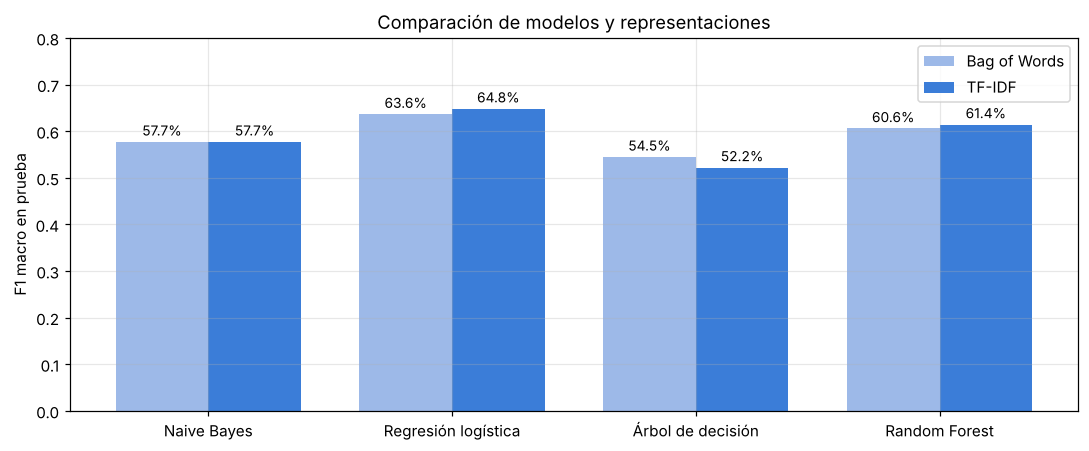

In [18]:
fig, eje = plt.subplots(figsize=(10, 4.2))
orden = list(MODELOS)
ancho = 0.38
for k, (representacion, color) in enumerate([("Bag of Words", "#9DB9E8"), ("TF-IDF", "#3B7DD8")]):
    valores = [resultados.query("Modelo == @m and Representación == @representacion")["F1 macro"].item() for m in orden]
    barras = eje.bar(np.arange(len(orden)) + (k - 0.5) * ancho, valores, ancho, label=representacion, color=color)
    eje.bar_label(barras, labels=[f"{v:.1%}" for v in valores], fontsize=9, padding=2)
eje.set_xticks(range(len(orden)), orden); eje.set_ylim(0, 0.8); eje.set_ylabel("F1 macro en prueba")
eje.set_title("Comparación de modelos y representaciones"); eje.legend(loc="upper right")
plt.tight_layout(); plt.savefig(CARPETA_RESULTADOS / "comparacion_modelos.png", dpi=150); plt.show()

### Matriz de confusión de cada modelo (TF-IDF)
Cada fila es la emoción real y cada columna la predicha; los valores están normalizados por fila (qué porcentaje de cada emoción real se predijo como cada clase). La diagonal son los aciertos.

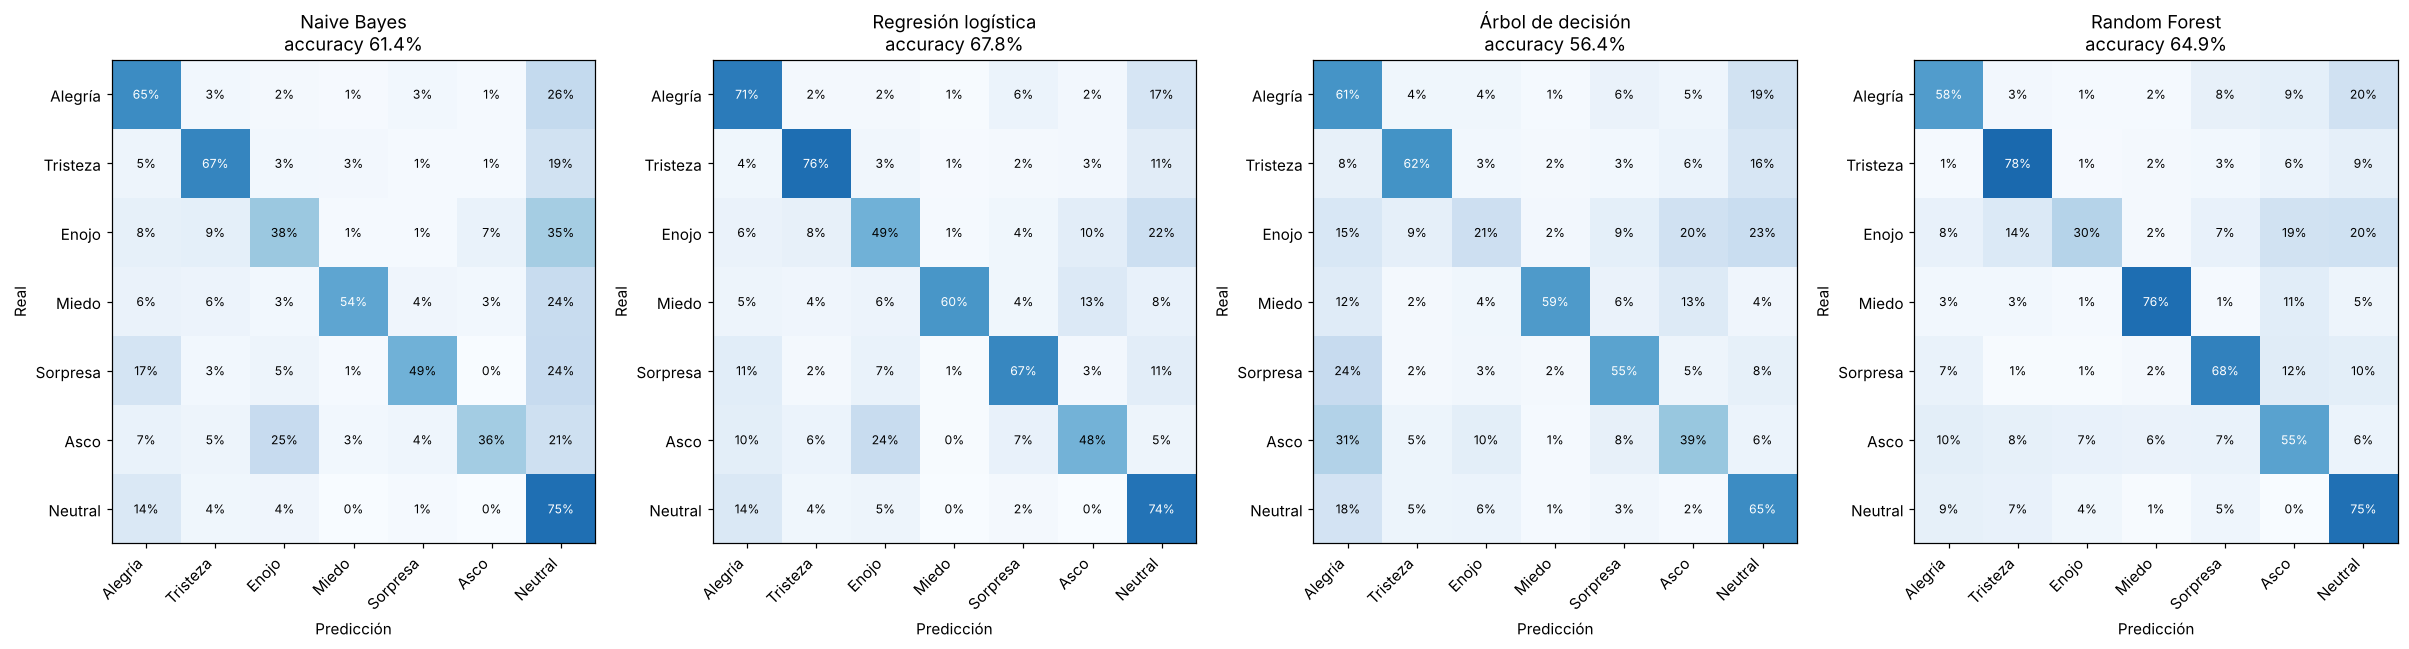

In [19]:
def dibujar_matriz(eje, y_real, y_pred, titulo):
    matriz = confusion_matrix(y_real, y_pred, labels=EMOCIONES)
    normal = matriz / matriz.sum(axis=1, keepdims=True)
    eje.imshow(normal, cmap="Blues", vmin=0, vmax=1)
    eje.set_xticks(range(7), EMOCIONES, rotation=45, ha="right"); eje.set_yticks(range(7), EMOCIONES)
    eje.set_xlabel("Predicción"); eje.set_ylabel("Real"); eje.set_title(titulo); eje.grid(False)
    for i in range(7):
        for j in range(7):
            eje.text(j, i, f"{normal[i, j]:.0%}", ha="center", va="center", fontsize=8,
                     color="white" if normal[i, j] > 0.5 else "black")


fig, ejes = plt.subplots(1, 4, figsize=(22, 5.5))
for eje, nombre in zip(ejes, MODELOS):
    modelo = entrenados[("TF-IDF", nombre)][2]
    pred = modelo.predict(X["TF-IDF"][2])
    dibujar_matriz(eje, y_test, pred, f"{nombre}\naccuracy {accuracy_score(y_test, pred):.1%}")
plt.tight_layout(); plt.show()

### Curvas ROC
La curva ROC muestra, para cada umbral de decisión, la tasa de verdaderos positivos frente a la de falsos positivos. Como hay 7 clases, se usa la estrategia **uno contra el resto** y se dibuja la curva promedio (*micro-average*) de cada modelo.

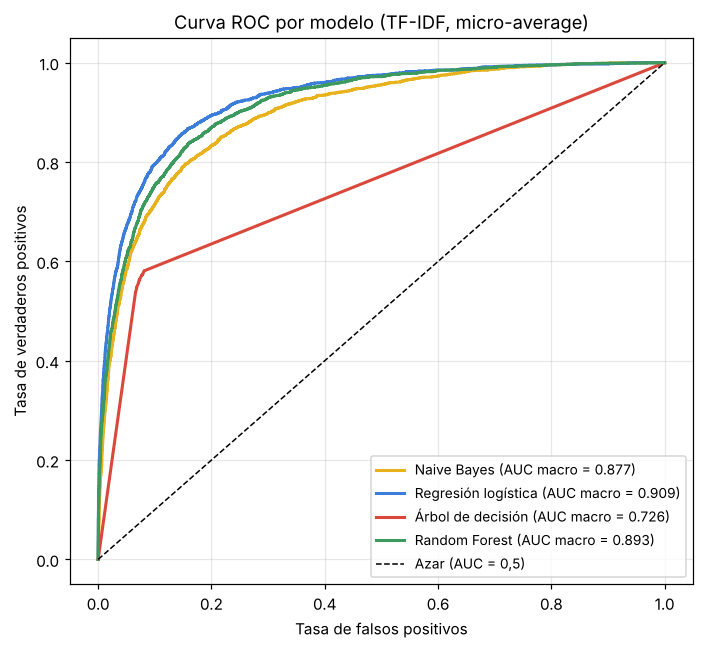

In [20]:
Y_bin = label_binarize(y_test, classes=EMOCIONES)
fig, eje = plt.subplots(figsize=(6.5, 6))
for nombre, color in zip(MODELOS, ["#E8B21F", "#3B7DD8", "#D9483B", "#3C9A5F"]):
    modelo = entrenados[("TF-IDF", nombre)][2]
    proba = pd.DataFrame(modelo.predict_proba(X["TF-IDF"][2]), columns=modelo.classes_)[EMOCIONES].to_numpy()
    fpr, tpr, _ = roc_curve(Y_bin.ravel(), proba.ravel())
    auc_macro = roc_auc_score(Y_bin, proba, average="macro")
    eje.plot(fpr, tpr, color=color, lw=2, label=f"{nombre} (AUC macro = {auc_macro:.3f})")
eje.plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC = 0,5)")
eje.set_xlabel("Tasa de falsos positivos"); eje.set_ylabel("Tasa de verdaderos positivos")
eje.set_title("Curva ROC por modelo (TF-IDF, micro-average)"); eje.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

## 11. Modelo final: mejora del mejor modelo

El mejor modelo fue **Regresión logística con TF-IDF**. Como mejora se añade una segunda representación: **n-gramas de caracteres** (fragmentos de 2 a 5 letras, como *"feli"* o *"mied"*). Así el modelo tolera errores de ortografía y variantes de palabras que el stemming no une (*"felisidad"*, *"felicísimo"*).

Se elige `C` con el conjunto de validación y luego el modelo final se reentrena con **entrenamiento + validación** (más datos) antes de evaluarlo una sola vez en prueba.

In [21]:
def crear_modelo_final(C):
    representacion = FeatureUnion([
        ("palabras", TfidfVectorizer(token_pattern=r"\S+", ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("caracteres", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True, max_features=100_000)),
    ])
    return Pipeline([("tfidf", representacion),
                     ("clasificador", LogisticRegression(C=C, max_iter=3000, class_weight="balanced"))])


busqueda_final = {}
for C in [1, 2, 4]:
    pred = crear_modelo_final(C).fit(train["procesado"], y_train).predict(valid["procesado"])
    busqueda_final[C] = f1_score(y_valid, pred, average="macro")
    print(f"C={C}: F1 macro en validación {busqueda_final[C]:.3f}")
C_final = max(busqueda_final, key=busqueda_final.get)

completo = pd.concat([train, valid], ignore_index=True)
modelo_final = crear_modelo_final(C_final).fit(completo["procesado"], completo["emocion"])
pred_final = modelo_final.predict(test["procesado"])
proba_final = pd.DataFrame(modelo_final.predict_proba(test["procesado"]), columns=modelo_final.classes_)[EMOCIONES].to_numpy()

base = resultados.iloc[0]
metricas_finales = {
    "accuracy": accuracy_score(y_test, pred_final),
    "precision_macro": precision_score(y_test, pred_final, average="macro"),
    "recall_macro": recall_score(y_test, pred_final, average="macro"),
    "f1_macro": f1_score(y_test, pred_final, average="macro"),
    "auc_macro": roc_auc_score(Y_bin, proba_final, average="macro"),
    "accuracy_sentimiento": float(np.mean([SENTIMIENTO[a] == SENTIMIENTO[b] for a, b in zip(y_test, pred_final)])),
}
pd.DataFrame({
    f"Mejor modelo base ({base['Modelo']}, {base['Representación']})": [base["Accuracy"], base["Precisión"], base["Recall"], base["F1 macro"], base["AUC macro"]],
    f"Modelo final (palabras + caracteres, C={C_final})": [metricas_finales[k] for k in ["accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_macro"]],
}, index=["Accuracy", "Precisión macro", "Recall macro", "F1 macro", "AUC macro"]).style.format("{:.3f}")

C=1: F1 macro en validación 0.636


C=2: F1 macro en validación 0.639


C=4: F1 macro en validación 0.633


,"Mejor modelo base (Regresión logística, TF-IDF)","Modelo final (palabras + caracteres, C=2)"
Accuracy,0.678,0.681
Precisión macro,0.668,0.663
Recall macro,0.635,0.659
F1 macro,0.648,0.660
AUC macro,0.909,0.920


In [22]:
print(f"Accuracy del sentimiento (positivo / negativo / neutral): {metricas_finales['accuracy_sentimiento']:.1%}\n")
print(classification_report(y_test, pred_final, labels=EMOCIONES, digits=3))

Accuracy del sentimiento (positivo / negativo / neutral): 75.9%

              precision    recall  f1-score   support

     Alegría      0.712     0.695     0.704       712
    Tristeza      0.794     0.783     0.789       355
       Enojo      0.467     0.508     0.487       240
       Miedo      0.808     0.688     0.743       141
    Sorpresa      0.610     0.692     0.649       276
        Asco      0.526     0.539     0.533       204
     Neutral      0.725     0.707     0.716       794

    accuracy                          0.681      2722
   macro avg      0.663     0.659     0.660      2722
weighted avg      0.686     0.681     0.683      2722



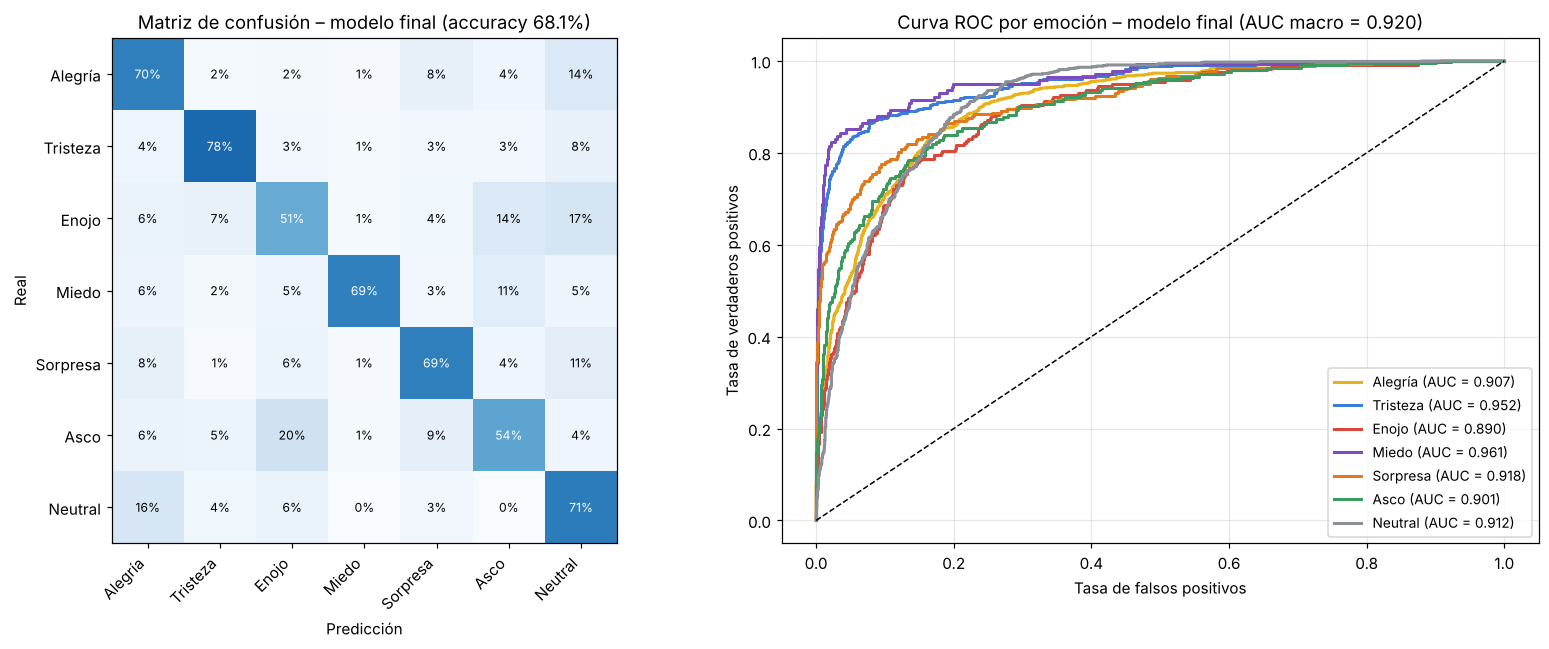

In [23]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 6))
dibujar_matriz(ejes[0], y_test, pred_final, f"Matriz de confusión – modelo final (accuracy {metricas_finales['accuracy']:.1%})")
for i, emocion in enumerate(EMOCIONES):
    fpr, tpr, _ = roc_curve(Y_bin[:, i], proba_final[:, i])
    ejes[1].plot(fpr, tpr, color=COLORES[emocion], lw=2, label=f"{emocion} (AUC = {auc(fpr, tpr):.3f})")
ejes[1].plot([0, 1], [0, 1], "k--", lw=1)
ejes[1].set_xlabel("Tasa de falsos positivos"); ejes[1].set_ylabel("Tasa de verdaderos positivos")
ejes[1].set_title(f"Curva ROC por emoción – modelo final (AUC macro = {metricas_finales['auc_macro']:.3f})")
ejes[1].legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.savefig(CARPETA_RESULTADOS / "matriz_confusion_y_roc.png", dpi=150); plt.show()

## 12. Visualización de resultados

### WordCloud: términos más frecuentes por emoción
Cada nube muestra las palabras más frecuentes de los textos de entrenamiento de una emoción (después de limpiar y quitar stopwords; sin stemming, para que se lean palabras completas). El tamaño es proporcional a la frecuencia.

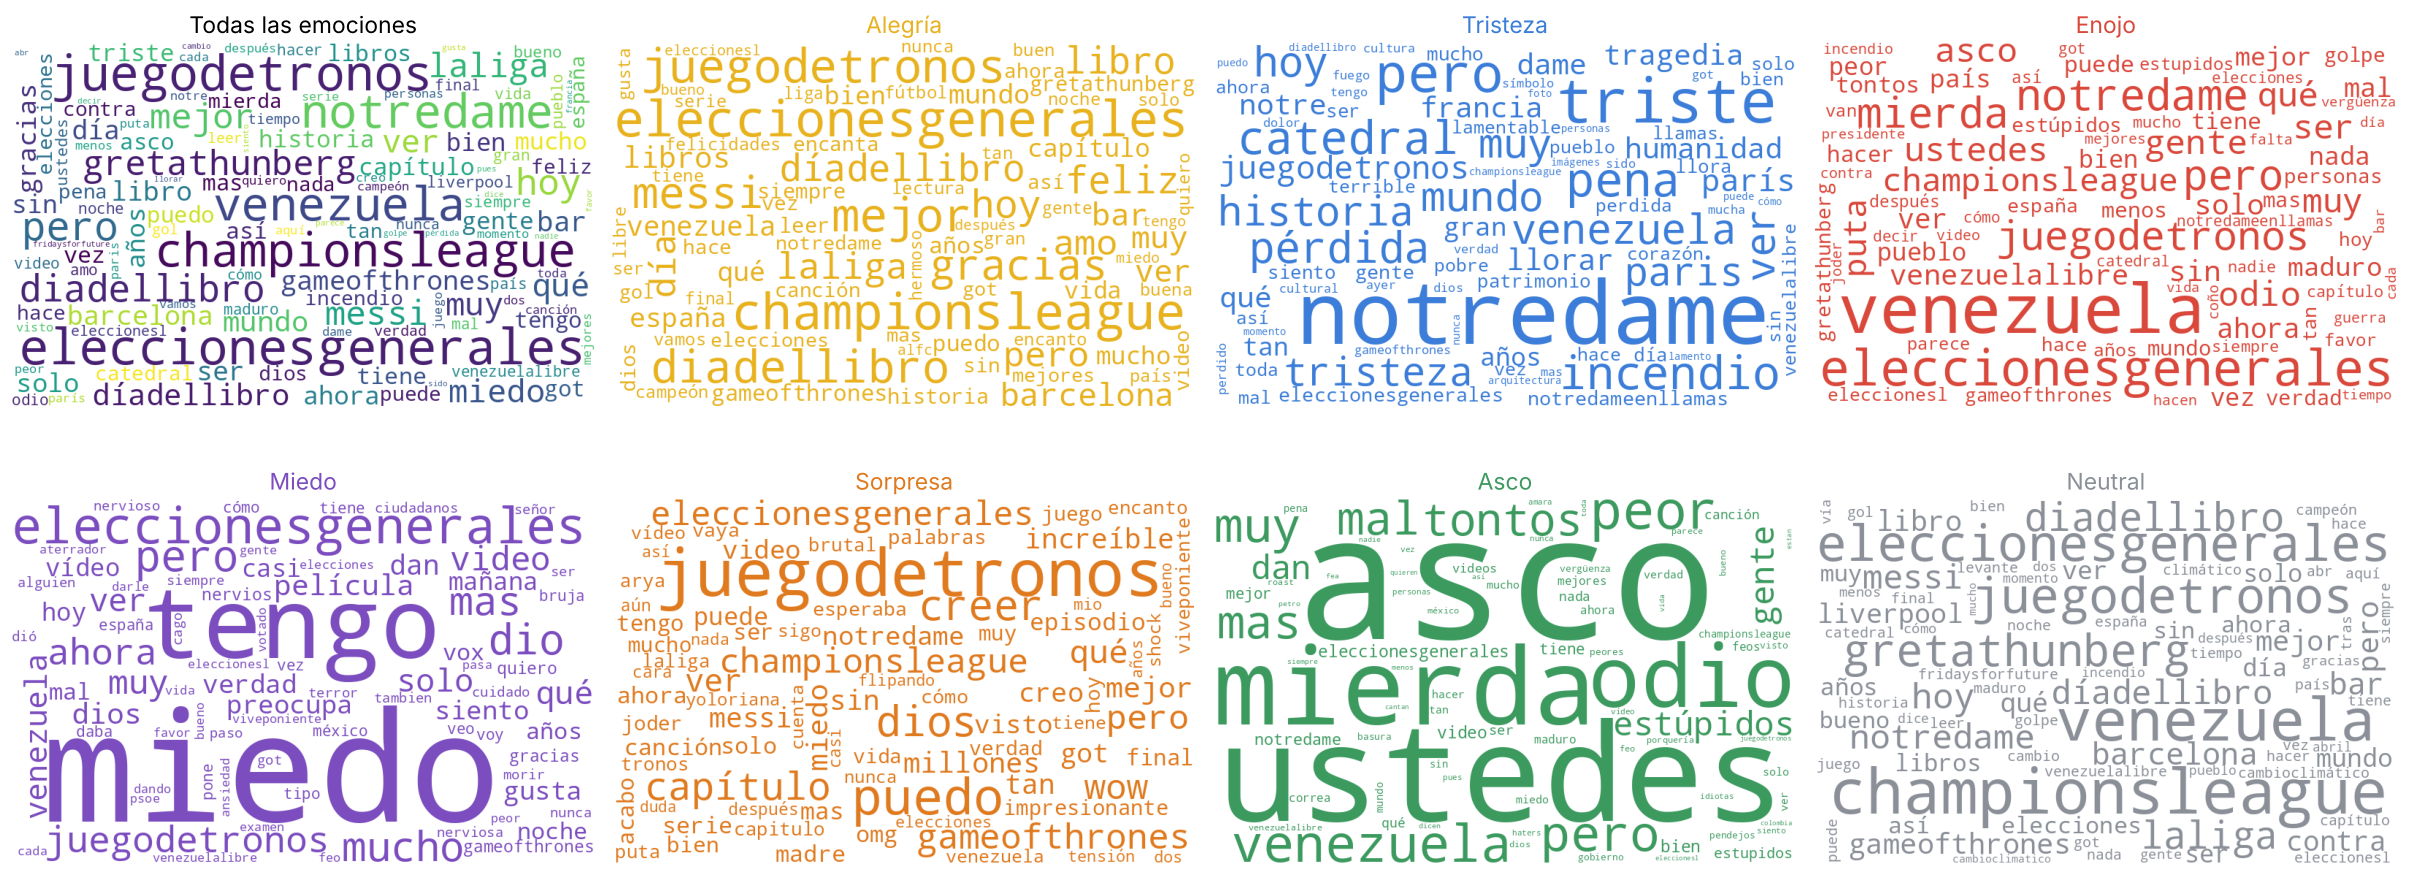

In [24]:
def palabras_para_nube(textos):
    tokens = [w for t in textos for w in quitar_stopwords(tokenizar(limpiar(t)))
              if w not in {"!", "?", "jaja"} and not w.startswith(("emoji_", "emoticono_")) and len(w) > 2]
    return " ".join(tokens)


fig, ejes = plt.subplots(2, 4, figsize=(22, 9))
nube_general = WordCloud(width=800, height=500, background_color="white", colormap="viridis", collocations=False, normalize_plurals=False,
                         max_words=120, random_state=SEMILLA).generate(palabras_para_nube(train["texto"]))
ejes[0, 0].imshow(nube_general); ejes[0, 0].set_title("Todas las emociones", fontsize=15)
for eje, emocion in zip(ejes.flat[1:], EMOCIONES):
    nube = WordCloud(width=800, height=500, background_color="white", collocations=False, normalize_plurals=False, max_words=80,
                     color_func=lambda *a, c=COLORES[emocion], **k: c, random_state=SEMILLA
                     ).generate(palabras_para_nube(train.loc[train["emocion"] == emocion, "texto"]))
    eje.imshow(nube); eje.set_title(emocion, fontsize=15, color=COLORES[emocion])
for eje in ejes.flat:
    eje.axis("off")
plt.tight_layout(); plt.savefig(CARPETA_RESULTADOS / "wordcloud.png", dpi=120); plt.show()

### Palabras con más peso en el modelo final
La regresión logística es **interpretable**: cada término tiene un peso por emoción. Estos son los términos (raíces) con mayor peso positivo para cada emoción.

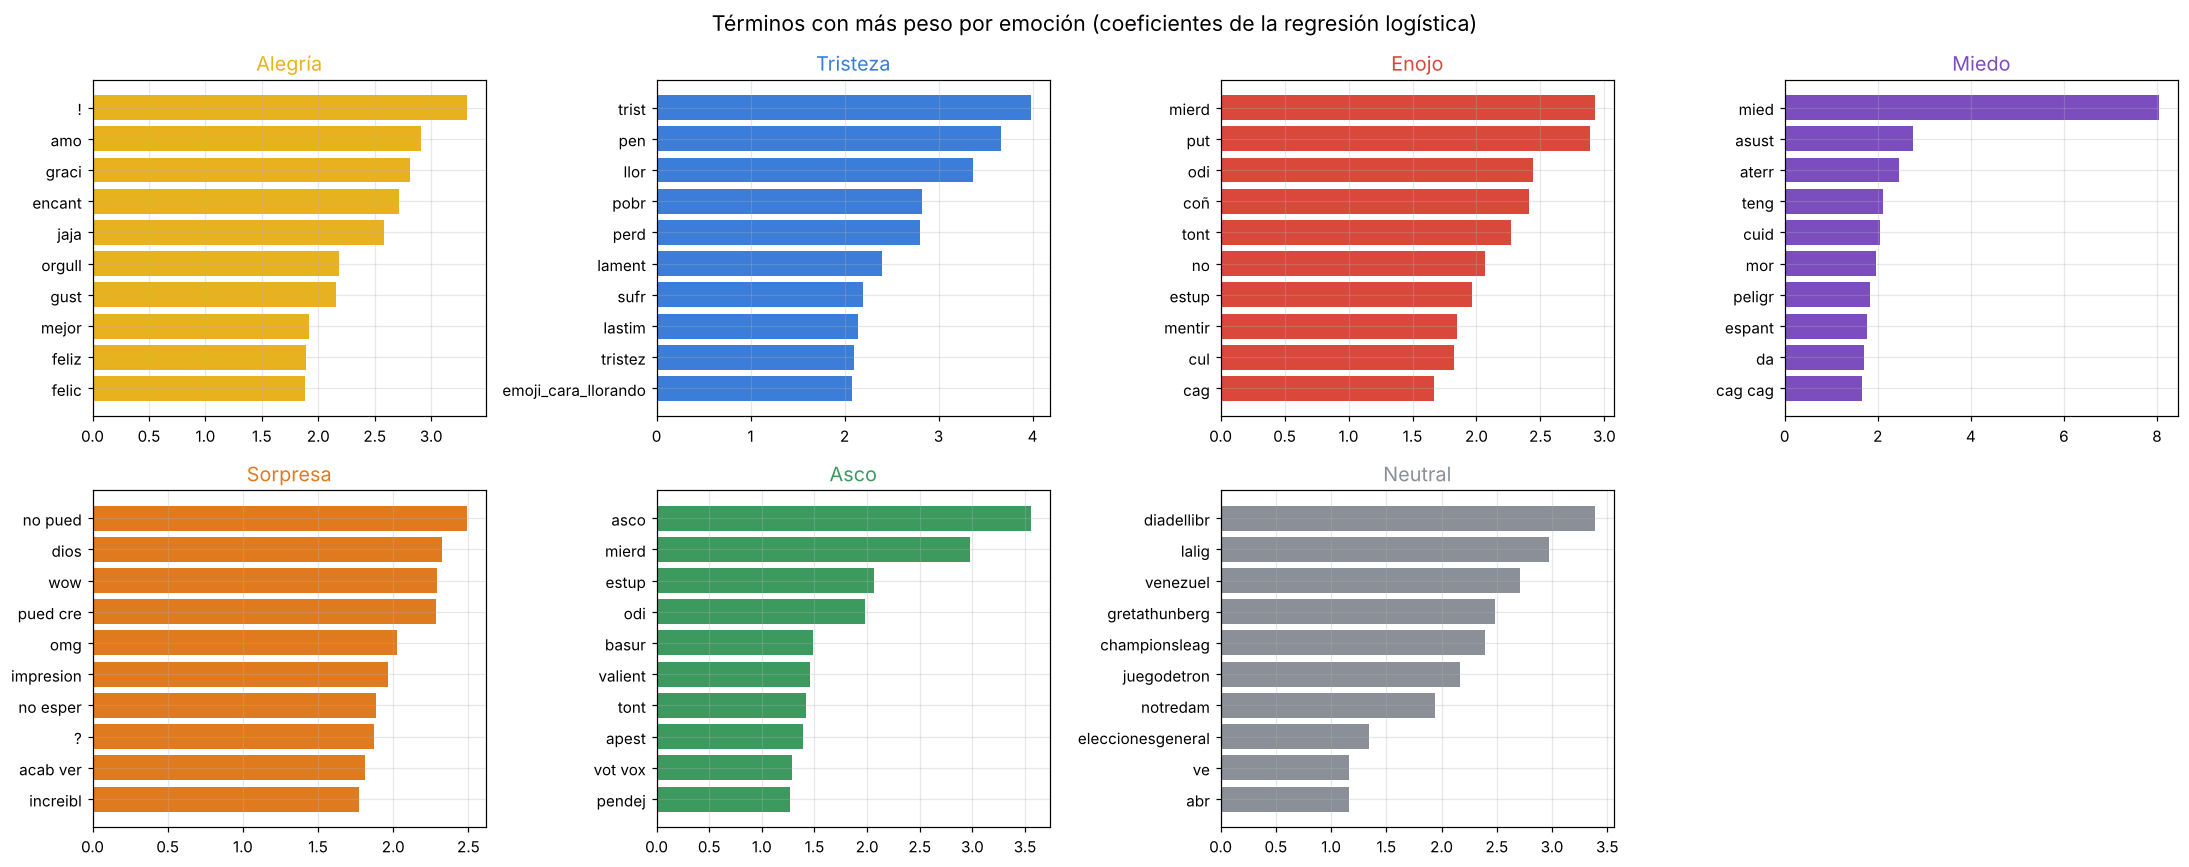

In [25]:
vectorizador_palabras = modelo_final.named_steps["tfidf"].transformer_list[0][1]
terminos = vectorizador_palabras.get_feature_names_out()
pesos = modelo_final.named_steps["clasificador"].coef_[:, :len(terminos)]
clases = list(modelo_final.classes_)

fig, ejes = plt.subplots(2, 4, figsize=(20, 8))
for eje, emocion in zip(ejes.flat, EMOCIONES):
    fila = pesos[clases.index(emocion)]
    top = np.argsort(fila)[::-1][:10]
    eje.barh(range(10)[::-1], fila[top], color=COLORES[emocion])
    eje.set_yticks(range(10)[::-1], terminos[top]); eje.set_title(emocion, color=COLORES[emocion], fontsize=13)
ejes.flat[-1].axis("off")
fig.suptitle("Términos con más peso por emoción (coeficientes de la regresión logística)", fontsize=14)
plt.tight_layout(); plt.savefig(CARPETA_RESULTADOS / "palabras_clave.png", dpi=130); plt.show()

### Términos más importantes para Random Forest
Random Forest mide la importancia de cada término según cuánto ayuda a separar las clases en sus árboles. A diferencia de la regresión logística, no dice a qué emoción apunta cada término.

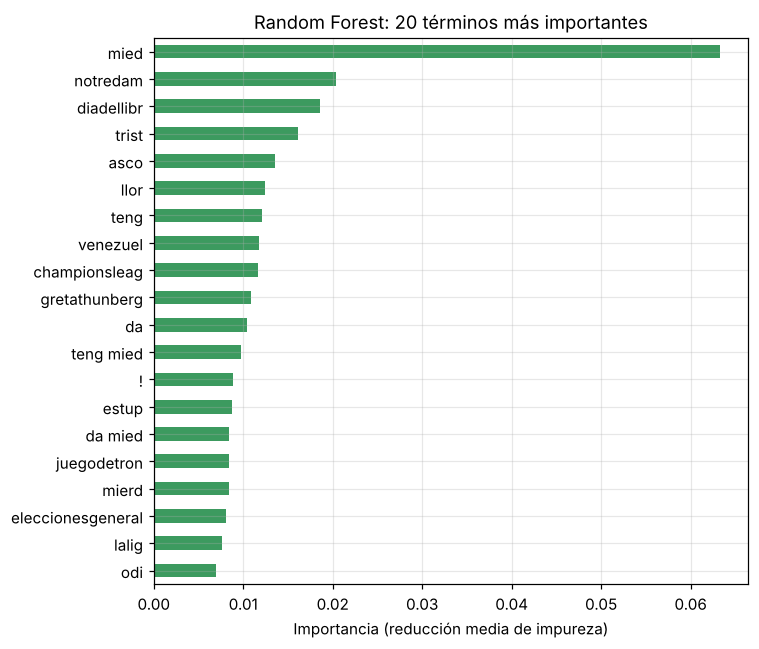

In [26]:
rf = entrenados[("TF-IDF", "Random Forest")][2]
nombres_tfidf = REPRESENTACIONES["TF-IDF"].get_feature_names_out()
importancia = pd.Series(rf.feature_importances_, index=nombres_tfidf).nlargest(20)
importancia[::-1].plot.barh(figsize=(7, 6), color="#3C9A5F", title="Random Forest: 20 términos más importantes")
plt.xlabel("Importancia (reducción media de impureza)"); plt.tight_layout(); plt.show()

### Análisis de errores
Algunos textos de prueba que el modelo final clasificó mal:

In [27]:
errores = test.assign(prediccion=pred_final)[lambda d: d["emocion"] != d["prediccion"]]
errores.sample(10, random_state=3)[["texto", "emocion", "prediccion"]].rename(columns={"emocion": "real"})

,texto,real,prediccion
1203,USER Qué dolor de gónadas tan bravo! Me duele como ser humano pero sobre todo como historiador. Que se salven su est...,Enojo,Tristeza
816,"Que bien está jugando Vidal, espero que siga jugando el 2do tiempo 👌 #ChampionsLeague",Alegría,Neutral
1130,"Hostia puta!!! Capitulazoooo, q sea ya Domingo otra vez!!! #VivePoniente #got #JuegoDeTronos",Alegría,Sorpresa
2441,Las EPS son una porquería,Enojo,Asco
2077,"Conocé a #GretaThunberg, la joven activista que enfrenta la #crisisclimática. Con tan sólo 16 años y movilizada por ...",Alegría,Neutral
1097,¡Hoy en todo Chile marchamos por más consciencia y la urgencia de hacer cambios por los efectos del #cambioclimático...,Enojo,Neutral
2171,#NotreDameEnLlamas Bombero entró en puntas de pie para que el fuego no se avive.,Neutral,Sorpresa
805,"When ese robot me da terror xd, me gustaría decirle que opina sobre la humanidad sinceramente xdd",Miedo,Alegría
1919,No sé por que me cuesta tanto entender la matemática :( Ojala todos los profesores de matemática fueran como usted,Tristeza,Asco
769,"Nunca habia visto tanta caca junta, es un espectaculo muy impresionante ATT: Bodoque",Asco,Sorpresa


### Prueba con frases nuevas

In [28]:
def analizar(texto):
    """Emoción, confianza y sentimiento de un texto nuevo."""
    probs = pd.Series(modelo_final.predict_proba([preprocesar(texto)])[0], index=modelo_final.classes_)
    por_sentimiento = probs.groupby(probs.index.map(SENTIMIENTO)).sum()
    return {"Texto": texto, "Emoción": probs.idxmax(), "Confianza": probs.max(),
            "Sentimiento": por_sentimiento.idxmax(), "Prob. sentimiento": por_sentimiento.max()}


frases = ["¡Por fin me dieron la beca! No lo puedo creer, estoy feliz 😄",
          "Se murió mi perrito 😭",
          "Me da mucho miedo caminar sola por esa calle de noche",
          "Qué asco, encontré un pelo en la sopa",
          "¿En serio ganamos en el último minuto? ¡Increíble!",
          "Estoy harto de que cancelen el vuelo, pésimo servicio",
          "Mañana a las 10 es la reunión del proyecto",
          "Pues qué maravilla, otra vez se cayó la aplicación"]
pd.DataFrame([analizar(f) for f in frases]).style.format({"Confianza": "{:.0%}", "Prob. sentimiento": "{:.0%}"})

,Texto,Emoción,Confianza,Sentimiento,Prob. sentimiento
0,"¡Por fin me dieron la beca! No lo puedo creer, estoy feliz 😄",Alegría,51%,Positivo,51%
1,Se murió mi perrito 😭,Tristeza,84%,Negativo,96%
2,Me da mucho miedo caminar sola por esa calle de noche,Miedo,96%,Negativo,98%
3,"Qué asco, encontré un pelo en la sopa",Asco,79%,Negativo,83%
4,¿En serio ganamos en el último minuto? ¡Increíble!,Sorpresa,93%,Neutral,93%
5,"Estoy harto de que cancelen el vuelo, pésimo servicio",Asco,49%,Negativo,77%
6,Mañana a las 10 es la reunión del proyecto,Neutral,20%,Negativo,50%
7,"Pues qué maravilla, otra vez se cayó la aplicación",Alegría,56%,Positivo,56%


### Guardar el modelo
El modelo final se guarda en `modelo/` para usarlo en la aplicación web (`streamlit run app.py`) y en la consola (`python predecir.py`).

In [29]:
joblib.dump(modelo_final, CARPETA_MODELO / "modelo.joblib", compress=3)
meta = {
    "modelo": "TF-IDF (palabras + caracteres) + Regresión logística",
    "preprocesamiento": "limpieza, tokenización, stopwords (NLTK, conservando negaciones), stemming Snowball",
    "C": C_final,
    "etiquetas": list(modelo_final.classes_),
    "textos_entrenamiento": int(len(completo)),
    "prueba": {k: round(float(v), 4) for k, v in metricas_finales.items()} | {"textos": int(len(test))},
    "comparacion": resultados.round(4).to_dict("records"),
    "fecha": datetime.now().isoformat(timespec="seconds"),
}
(CARPETA_MODELO / "meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print("Modelo guardado en", CARPETA_MODELO / "modelo.joblib")

Modelo guardado en modelo/modelo.joblib


## 13. Discusión y conclusiones

### ¿Qué desafíos tuvo el preprocesamiento de texto?

- **Texto de redes sociales.** Los tuits traen emojis, risas escritas de muchas formas ("jajaja", "jsjs", "xD"), letras repetidas ("feliiiiz"), menciones y hashtags. Se normalizaron con expresiones regulares y los emojis se **convirtieron en palabras** en lugar de eliminarse, porque expresan emoción (😭, 🤢).
- **Stopwords que sí importan.** La lista de NLTK incluye "no", "ni", "sin", "nada", "muy" o "qué", que cambian la emoción de la frase ("estoy feliz" frente a "no estoy feliz"). Se conservaron 19 de esas palabras y se eliminaron las otras 295.
- **Stemming imperfecto.** Snowball une variantes (*felicidad, felices → felic*), pero no todas (*felicísimo → felicisim*). Aun así, combinado con la eliminación de stopwords subió el F1 macro en validación de **60,7 % a 63,1 %** y redujo el vocabulario de **25.506 a 15.257 términos**. Por separado aportaban poco: solo stopwords 60,7 %, solo stemming 61,3 %.
- **Calidad de los datos.** Las etiquetas del archivo de prueba de EmoEvent estaban desalineadas; sin corregir 1.050 de ellas, la evaluación habría sido inválida. Además, las clases están desbalanceadas (382 textos de Miedo frente a 2.781 Neutrales) y los hashtags de eventos de 2019 (*juegodetronos, eleccionesgenerales, championsleague*) dominan las frecuencias de todas las emociones, como muestra la WordCloud: es un **sesgo temático** del dataset.

### ¿Cuál modelo se comportó mejor y por qué?

| Modelo (mejor representación) | Accuracy | F1 macro | AUC macro |
|---|---|---|---|
| **Regresión logística (TF-IDF)** | **67,8 %** | **64,8 %** | **0,909** |
| Random Forest (TF-IDF) | 64,9 % | 61,4 % | 0,893 |
| Naive Bayes (TF-IDF / BoW) | 61,4 % / 61,0 % | 57,7 % | 0,877 / 0,865 |
| Árbol de decisión (BoW) | 57,7 % | 54,5 % | 0,743 |

- **Regresión logística** fue la mejor. Los modelos lineales funcionan muy bien con texto, porque cada texto es un vector enorme y disperso (15.257 términos, solo el 0,09 % de celdas distintas de cero) y cada término suma su aporte de forma independiente. La regularización (`C`) evita que memorice palabras raras y `class_weight` compensa el desbalance. Además es rápida (≈1 s) e **interpretable**.
- **Naive Bayes** es el más rápido (0,02 s), pero supone que las palabras son independientes y favorece las clases frecuentes. Con TF-IDF tiene buena precisión (63,4 %) pero bajo recall (54,7 %): se le escapan las emociones con pocos ejemplos.
- **Un solo árbol de decisión** fue el peor (AUC 0,73). Con miles de términos dispersos, cada rama se basa en pocas palabras concretas y el árbol se sobreajusta.
- **Random Forest** corrige ese problema promediando 300 árboles: +7 puntos de F1 respecto a un solo árbol. Aun así queda por debajo de la regresión logística y es unas 4 veces más lento.
- **TF-IDF superó a Bag of Words** en regresión logística y Random Forest, porque da más peso a los términos distintivos. En Naive Bayes ambas dieron el mismo F1 (57,7 %), ya que ese modelo está pensado para conteos.

El **modelo final** (regresión logística con TF-IDF de palabras **y de fragmentos de caracteres**, reentrenado con entrenamiento + validación) obtuvo en prueba **68,1 % de accuracy, 66,0 % de F1 macro y AUC macro de 0,920**. En el sentimiento (positivo/negativo/neutral) acierta el **75,9 %**. Por emoción, las mejores son Tristeza (F1 0,79) y Miedo (0,74); las más difíciles, Asco (0,53) y Enojo (0,49), que se confunden entre sí (el 20 % del Asco se predice como Enojo) y con Neutral (17 % del Enojo). Como referencia, adivinar al azar entre 7 clases daría ~14 %, y en la competencia EmoEvalEs 2021 (IberLEF), que usó EmoEvent, los mejores sistemas, en su mayoría Transformers, obtuvieron entre 69 % y 73 % de accuracy.

### ¿Cómo se podría mejorar el rendimiento?

1. **Más datos y más equilibrados**, sobre todo de Miedo, Asco y Enojo, y datos del dominio donde se vaya a usar (reseñas, encuestas).
2. **Reducir el sesgo temático**, por ejemplo eliminando los hashtags de eventos o reemplazándolos por un token genérico.
3. **Lematización** con spaCy en lugar de stemming, para unir mejor las variantes de cada palabra.
4. **Búsqueda de hiperparámetros más amplia** con validación cruzada (`GridSearchCV`).
5. **Representaciones con contexto**: embeddings (word2vec, fastText) o Transformers en español (BETO, RoBERTuito), que manejan mejor la negación, la ironía y el orden de las palabras.
6. **Clasificación multietiqueta**, porque un texto puede expresar varias emociones a la vez.

### Conclusiones

1. Se implementó el flujo completo de un proyecto de PLN: carga del dataset → limpieza → tokenización → stopwords y stemming → representación (Bag of Words y TF-IDF) → entrenamiento de cuatro modelos → evaluación (precisión, recall, F1, matriz de confusión, ROC/AUC) → visualización (WordCloud, términos clave).
2. El preprocesamiento importa: limpiar, quitar stopwords **conservando las negaciones** y aplicar stemming mejoró el F1 en 2,4 puntos con un vocabulario 40 % más pequeño.
3. La **regresión logística con TF-IDF** ofreció el mejor equilibrio entre precisión, velocidad e interpretabilidad. Los modelos de árboles no aprovechan bien los vectores de texto dispersos.
4. El modelo reconoce bien las emociones expresadas con palabras claras ("miedo", "triste", "asco"), pero falla con el **sarcasmo**: *"Pues qué maravilla, otra vez se cayó la aplicación"* sale como Alegría. Además arrastra el sesgo temático de los datos y solo funciona en español.
5. El modelo final se guardó en `modelo/` y se usa en la aplicación web (`streamlit run app.py`), que permite escribir un texto o subir un archivo y ver la emoción, el sentimiento y las palabras que más influyeron.